# Diabetes Classification and Clustering

Nihal Mahato

## 1 Objective and environment

Explore the dataset, predict supplied N/P/Y labels, and compare them with groups discovered without labels. Model selection uses grouped validation inside training data; the final test set is reserved.

In [1]:
import sys
print(sys.executable)

c:\Users\NIHAL\Desktop\classification_project_items\.venv\Scripts\python.exe


In [2]:
from pathlib import Path 
print(Path.cwd())

c:\Users\NIHAL\Desktop\classification_project_items\notebooks


In [3]:
project_root = Path.cwd().resolve()
if not (project_root / "data" / "raw" / "dataset.xlsx").is_file():
    project_root = project_root.parent
data_path = project_root / "data" / "raw" / "dataset.xlsx"
if not data_path.is_file():
    raise FileNotFoundError("Place dataset.xlsx in data/raw and run from the project root or notebooks folder.")
print(data_path)
print("File exists:", data_path.is_file())

c:\Users\NIHAL\Desktop\classification_project_items\data\raw\dataset.xlsx
File exists: True


### Load the original spreadsheet

In [4]:
import pandas as pd 

df = pd.read_excel(data_path)
df.head() 

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,735,34221,M,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,420,47975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,680,87656,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,504,34223,M,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N


## 2 Data audit and label cleaning

In [5]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (1000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   No_Pation  1000 non-null   int64  
 2   Gender     1000 non-null   object 
 3   AGE        1000 non-null   int64  
 4   Urea       1000 non-null   float64
 5   Cr         1000 non-null   int64  
 6   HbA1c      1000 non-null   float64
 7   Chol       1000 non-null   float64
 8   TG         1000 non-null   float64
 9   HDL        1000 non-null   float64
 10  LDL        1000 non-null   float64
 11  VLDL       1000 non-null   float64
 12  BMI        1000 non-null   float64
 13  CLASS      1000 non-null   object 
dtypes: float64(8), int64(4), object(2)
memory usage: 109.5+ KB


In [6]:
for column in ["Gender", "CLASS"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))
    print("Exact values:", [repr(value) for value in df[column].unique()])


Gender:
Gender
M    565
F    434
f      1
Name: count, dtype: int64
Exact values: ["'F'", "'M'", "'f'"]

CLASS:
CLASS
Y     840
N     102
P      53
Y       4
N       1
Name: count, dtype: int64
Exact values: ["'N'", "'N '", "'P'", "'Y'", "'Y '"]


In [7]:
df_clean = df.copy()

for column in ["Gender", "CLASS"]:
    df_clean[column] = df_clean[column].str.strip().str.upper()

In [8]:
print("Shape unchanged:", df_clean.shape == df.shape)

for column in ["Gender", "CLASS"]:
    print(f"\n{column}:")
    print(df_clean[column].value_counts(dropna=False))
    print("Exact values:", [repr(value) for value in df_clean[column].unique()])

Shape unchanged: True

Gender:
Gender
M    565
F    435
Name: count, dtype: int64
Exact values: ["'F'", "'M'"]

CLASS:
CLASS
Y    844
N    103
P     53
Name: count, dtype: int64
Exact values: ["'N'", "'P'", "'Y'"]


Standardized capitalization and removed surrounding whitespace in Gender and CLASS. All 1,000 rows were preserved. Class counts are Y: 844, N: 103, and P: 53, indicating substantial class imbalance.

### Repeated records and identifier checks

In [9]:
record_columns = df_clean.columns.drop(["ID", "No_Pation"])

print("Exact duplicate rows:", df_clean.duplicated().sum())
print(
    "Repeated records excluding identifiers:",
    df_clean.duplicated(subset=record_columns).sum()
)

Exact duplicate rows: 0
Repeated records excluding identifiers: 174


In [10]:
repeated_mask = df_clean.duplicated(
    subset=record_columns,
    keep=False
)

df_clean.loc[repeated_mask].sort_values(
    by=list(record_columns)
).head(10)

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
12,82,46815,F,30,3.0,42,4.1,4.9,1.3,1.2,3.2,0.5,22.0,N
17,676,87654,F,30,3.0,42,4.1,4.9,1.3,1.2,3.2,0.5,22.0,N
129,466,26665,F,30,5.7,53,6.0,5.4,1.7,1.4,3.3,0.7,22.0,P
131,688,87660,F,30,5.7,53,6.0,5.4,1.7,1.4,3.3,0.7,22.0,P
205,140,24018,F,33,1.8,31,7.4,3.7,1.2,1.6,1.5,0.5,31.5,Y
211,453,48112,F,33,1.8,31,7.4,3.7,1.2,1.6,1.5,0.5,31.5,Y
121,399,47513,F,39,3.0,38,6.4,4.7,1.3,1.1,3.1,0.6,22.0,P
125,690,87661,F,39,3.0,38,6.4,4.7,1.3,1.1,3.1,0.6,22.0,P
21,97,12744,F,42,5.0,73,4.5,6.2,1.0,1.1,4.6,0.4,24.0,N
33,678,87655,F,42,5.0,73,4.5,6.2,1.0,1.1,4.6,0.4,24.0,N


In [11]:
for column in ["ID", "No_Pation"]:
    print(f"\n{column}:")
    print("Unique values:", df_clean[column].nunique())
    print("Repeated entries after first:", df_clean[column].duplicated().sum())


ID:
Unique values: 800
Repeated entries after first: 200

No_Pation:
Unique values: 961
Repeated entries after first: 39


In [12]:
patient_repeat_mask = df_clean["No_Pation"].duplicated(keep=False)

df_clean.loc[patient_repeat_mask].sort_values("No_Pation").head(10)

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
697,576,234,M,66,4.10,63,10.1,3.6,5.1,0.9,2.5,0.9,30.0,Y
599,584,234,M,59,4.20,56,10.5,4.9,2.1,1.1,2.5,0.9,28.0,Y
664,554,345,M,55,4.40,56,10.0,4.9,2.1,1.1,2.5,0.9,28.0,Y
947,122,345,M,60,3.30,59,7.6,3.5,1.0,1.3,1.5,0.7,30.0,Y
868,28,856,F,55,8.50,59,7.6,3.3,1.7,0.9,1.7,0.8,32.0,Y
672,586,856,F,61,4.30,56,12.1,4.4,2.0,1.0,2.5,0.9,29.0,Y
425,601,2345,M,55,4.16,60,7.6,6.5,2.1,1.3,4.3,14.5,34.5,Y
892,55,2345,M,55,26.40,228,7.1,4.1,1.9,1.3,2.0,0.9,27.0,Y
781,548,14389,F,60,4.10,56,13.1,4.4,2.0,1.0,2.5,0.9,29.0,Y
171,231,14389,F,50,4.00,56,13.7,4.4,2.0,1.0,2.5,0.9,29.0,Y


Neither identifier is unique. Repeated No_Pation values can have different measurements. Patient identity is uncertain, so identifier-based deletion is not justified. Identifiers will be excluded from model inputs, and possible patient overlap will be considered when designing evaluation.

### Numeric quality audit

In [13]:
numeric_columns = df_clean.select_dtypes(include="number").columns
measurement_columns = numeric_columns.drop(["ID", "No_Pation"])

df_clean[measurement_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,1000.0,53.528000,8.799241,20.0,51.0,55.0,59.0,79.00
Urea,1000.0,5.124743,2.935165,0.5,3.7,4.6,5.7,38.90
Cr,1000.0,68.943000,59.984747,6.0,48.0,60.0,73.0,800.00
HbA1c,1000.0,8.281160,2.534003,0.9,6.5,8.0,10.2,16.00
Chol,1000.0,4.862820,1.301738,0.0,4.0,4.8,5.6,10.30
TG,1000.0,2.349610,1.401176,0.3,1.5,2.0,2.9,13.80
HDL,1000.0,1.204750,0.660414,0.2,0.9,1.1,1.3,9.90
LDL,1000.0,2.609790,1.115102,0.3,1.8,2.5,3.3,9.90
VLDL,1000.0,1.854700,3.663599,0.1,0.7,0.9,1.5,35.00
BMI,1000.0,29.578020,4.962388,19.0,26.0,30.0,33.0,47.75


In [14]:
zero_chol_mask = df_clean["Chol"] == 0

print("Rows with zero cholesterol:", zero_chol_mask.sum())
df_clean.loc[zero_chol_mask]

Rows with zero cholesterol: 1


,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
99,186,454316,M,77,5.0,106,5.4,0.0,2.8,0.8,1.8,0.7,19.0,N


In [15]:
for column in ["Cr", "HDL", "VLDL"]:
    print(f"\nHighest values for {column}:")
    display(df_clean.nlargest(3, column))

print("\nLowest HbA1c values:")
display(df_clean.nsmallest(3, "HbA1c"))


Highest values for Cr:


,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
273,1,34325,M,58,20.8,800,9.1,6.6,2.9,1.1,4.3,1.3,33.0,Y
283,266,24060,M,58,20.8,800,9.1,6.6,2.9,1.1,4.3,1.3,33.0,Y
846,1,34325,M,56,20.8,800,9.0,4.6,2.0,1.2,2.5,0.9,35.0,Y



Highest values for HDL:


,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
752,154,34522,F,56,4.5,57,11.8,3.9,3.1,9.9,1.8,1.4,33.0,Y
816,181,45511,F,55,5.5,50,12.2,6.3,2.3,9.0,4.4,1.0,31.0,Y
412,443,24119,F,52,6.4,88,8.5,8.5,0.8,6.6,1.3,1.3,33.0,Y



Highest values for VLDL:


,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
526,604,876543,M,66,5.50,73,10.9,9.3,5.1,0.9,6.4,35.0,27.75,Y
565,624,356355,M,55,6.66,61,6.7,2.5,4.9,0.8,0.5,33.6,29.00,Y
242,203,24039,M,55,5.00,76,10.2,5.6,4.6,0.8,2.9,31.8,33.90,Y



Lowest HbA1c values:


,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
80,138,45399,F,57,4.6,97,0.9,3.2,1.3,0.9,3.0,1.1,22.0,N
92,161,45406,F,60,7.5,70,0.9,3.4,5.3,1.1,3.6,0.8,24.0,N
98,182,454316,M,60,7.5,70,0.9,3.4,5.3,1.1,3.6,0.8,24.0,N


Numeric inspection identified extreme values in Cr, HDL, and VLDL, low HbA1c values, and one zero cholesterol value. Their validity and measurement units require verification. Values are retained pending a documented handling decision. Repeated identifiers do not consistently correspond to identical records.

## Data audit findings

- Dataset: 1,000 rows and 14 columns.
- No missing values were detected by pandas.
- Standardized capitalization and surrounding whitespace in Gender and CLASS.
- Cleaned class counts: Y = 844, N = 103, P = 53.
- Found 0 exact duplicate rows.
- Found 174 repeated rows after the first occurrence when excluding identifiers.
- Neither ID nor No_Pation is unique; patient identity remains uncertain.
- Flagged zero cholesterol and unusual numeric extremes for investigation.
- Retained all rows and numeric values during this initial audit.
- Identifiers will be excluded from model inputs.
- Identical feature records must remain together during evaluation splitting.

In [16]:
feature_columns = df_clean.columns.drop(["ID", "No_Pation", "CLASS"])

print("Input columns:", feature_columns.tolist())
print(
    "Repeated feature rows:",
    df_clean.duplicated(subset=feature_columns).sum()
)

Input columns: ['Gender', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG', 'HDL', 'LDL', 'VLDL', 'BMI']
Repeated feature rows: 174


In [17]:
labels_per_group = df_clean.groupby(
    feature_columns.tolist(),
    dropna=False
)["CLASS"].nunique()

print("Feature groups with conflicting labels:", (labels_per_group > 1).sum())

Feature groups with conflicting labels: 0


Keeping identical feature records in the same split to prevent overlap.
Aiming for approximately 80% training and 20% testing, with all three
classes represented in both.

## 3 Grouped evaluation split

In [18]:
feature_groups = df_clean.groupby(
    feature_columns.tolist(),
    dropna=False
).ngroup()

print("Rows assigned a group:", feature_groups.notna().sum())
print("Distinct feature groups:", feature_groups.nunique())

Rows assigned a group: 1000
Distinct feature groups: 826


In [19]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X=df_clean[feature_columns],
        y=df_clean["CLASS"],
        groups=feature_groups
    )
)

print("Training rows:", len(train_idx))
print("Test rows:", len(test_idx))

Training rows: 799
Test rows: 201


In [20]:
train_groups = set(feature_groups.iloc[train_idx])
test_groups = set(feature_groups.iloc[test_idx])

print("Shared feature groups:", len(train_groups & test_groups))
print("Shared row positions:", len(set(train_idx) & set(test_idx)))
print("All rows covered:", len(set(train_idx) | set(test_idx)) == len(df_clean))

split_counts = pd.DataFrame({
    "Train": df_clean.iloc[train_idx]["CLASS"].value_counts(),
    "Test": df_clean.iloc[test_idx]["CLASS"].value_counts()
}).fillna(0).astype(int)

display(split_counts)

Shared feature groups: 0
Shared row positions: 0
All rows covered: True


,Train,Test
CLASS,,
Y,670,174
N,83,20
P,46,7


In [21]:
X_train = df_clean.iloc[train_idx][feature_columns].copy()
X_test = df_clean.iloc[test_idx][feature_columns].copy()

y_train = df_clean.iloc[train_idx]["CLASS"].copy()
y_test = df_clean.iloc[test_idx]["CLASS"].copy()

print("Training:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (799, 11) (799,)
Test: (201, 11) (201,)


## 4 Training data exploration

In [22]:
X_train[measurement_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,799.0,53.456821,8.681806,25.0,51.00,55.0,59.0,77.00
Urea,799.0,5.157025,2.877609,0.5,3.70,4.6,5.7,26.40
Cr,799.0,70.231539,64.721363,6.0,48.00,60.0,73.5,800.00
HbA1c,799.0,8.226358,2.503705,0.9,6.50,8.0,10.1,16.00
Chol,799.0,4.843930,1.295272,0.0,4.00,4.8,5.5,9.90
TG,799.0,2.336896,1.403599,0.3,1.45,2.0,2.9,13.80
HDL,799.0,1.203517,0.646114,0.2,0.90,1.1,1.3,9.90
LDL,799.0,2.595795,1.062486,0.3,1.80,2.5,3.3,7.90
VLDL,799.0,1.772716,3.521539,0.1,0.70,0.9,1.4,35.00
BMI,799.0,29.521915,4.993688,19.0,26.00,30.0,33.0,47.75


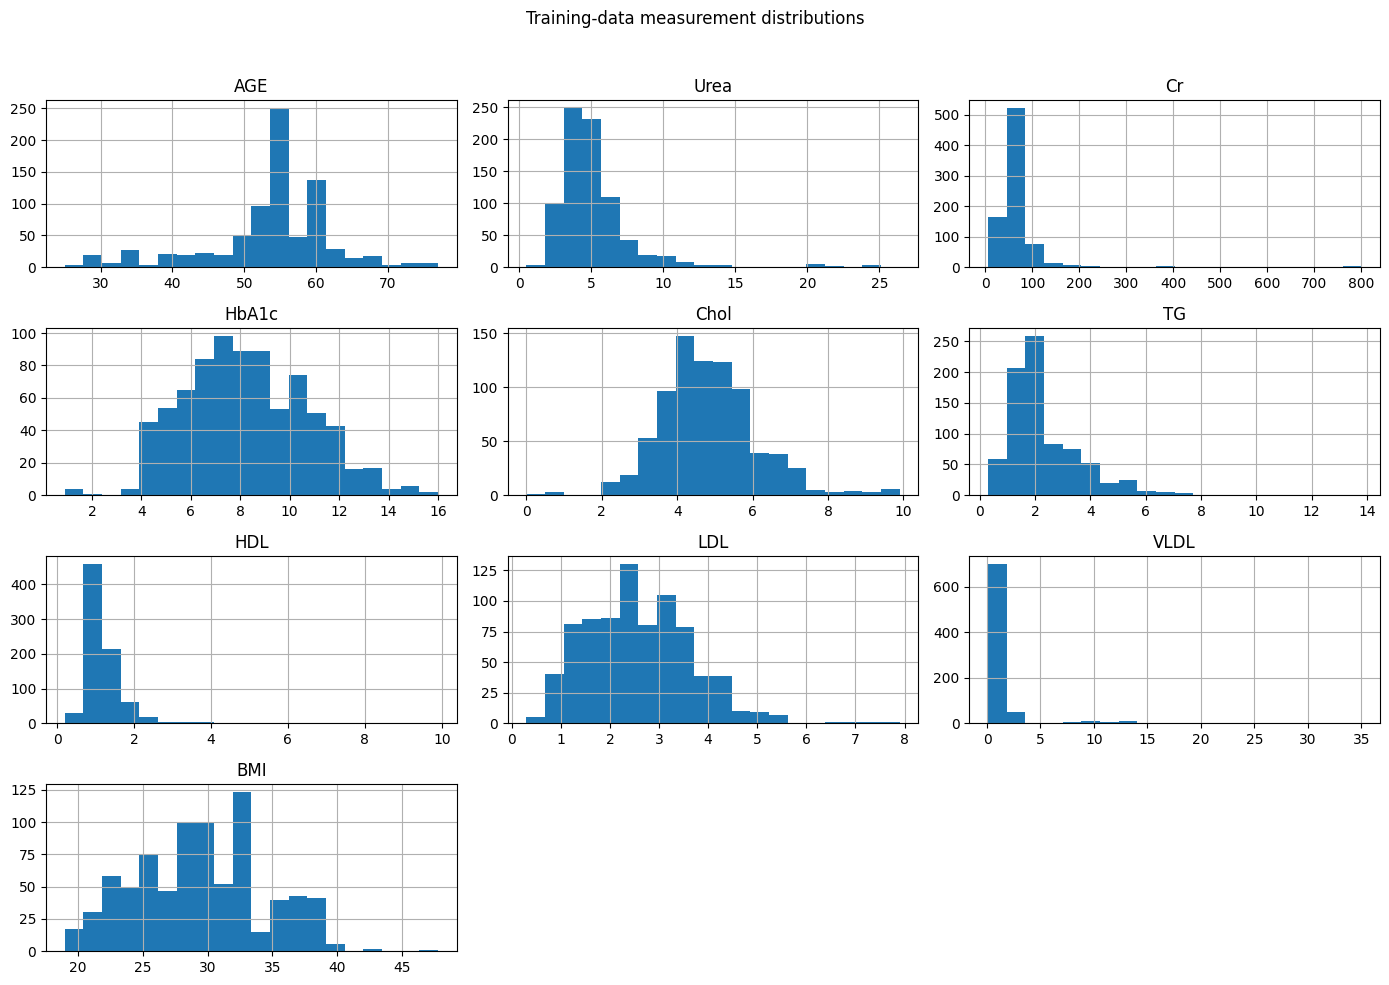

In [23]:
import matplotlib.pyplot as plt

X_train[measurement_columns].hist(
    bins=20,
    figsize=(14, 10)
)

plt.suptitle("Training-data measurement distributions")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## 5 Preprocessing

In [24]:
from sklearn.preprocessing import OneHotEncoder

gender_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

gender_encoded = gender_encoder.fit_transform(X_train[["Gender"]])

print(gender_encoder.get_feature_names_out(["Gender"]))
print(gender_encoded[:5])
print(X_train["Gender"].head().tolist())

['Gender_F' 'Gender_M']
[[1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [0. 1.]]
['F', 'M', 'F', 'F', 'M']


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), measurement_columns.tolist()),
        ("gender", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), ["Gender"])
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)

print("Prepared training shape:", X_train_prepared.shape)
print("Feature names:", preprocessor.get_feature_names_out())

Prepared training shape: (799, 12)
Feature names: ['numeric__AGE' 'numeric__Urea' 'numeric__Cr' 'numeric__HbA1c'
 'numeric__Chol' 'numeric__TG' 'numeric__HDL' 'numeric__LDL'
 'numeric__VLDL' 'numeric__BMI' 'gender__Gender_F' 'gender__Gender_M']


In [26]:
import numpy as np

print("All values finite:", np.isfinite(X_train_prepared).all())

numeric_count = len(measurement_columns)
numeric_means = X_train_prepared[:, :numeric_count].mean(axis=0)

print("Scaled numeric means:", np.round(numeric_means, 6))

All values finite: True
Scaled numeric means: [-0.  0. -0.  0. -0. -0.  0. -0.  0.  0.]


Initial preprocessing standardizes the ten numeric measurements and one-hot encodes Gender. Flagged numeric values are retained without correction because their validity is unverified. During model comparison, preprocessing will be fitted inside each training fold to prevent leakage.

## 6 Majority class baseline and grouped validation

In [27]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_train)

print("Classes predicted:", set(baseline_predictions))

Classes predicted: {np.str_('Y')}


In [28]:
training_groups = feature_groups.iloc[train_idx]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(
    cv.split(X_train, y_train, groups=training_groups)
)

for fold, (fit_idx, validation_idx) in enumerate(cv_splits, start=1):
    shared_groups = (
        set(training_groups.iloc[fit_idx])
        & set(training_groups.iloc[validation_idx])
    )

    print(
        f"Fold {fold}: "
        f"training={len(fit_idx)}, "
        f"validation={len(validation_idx)}, "
        f"shared groups={len(shared_groups)}"
    )

Fold 1: training=636, validation=163, shared groups=0
Fold 2: training=640, validation=159, shared groups=0
Fold 3: training=646, validation=153, shared groups=0
Fold 4: training=632, validation=167, shared groups=0
Fold 5: training=642, validation=157, shared groups=0


In [29]:
for fold, (fit_idx, validation_idx) in enumerate(cv_splits, start=1):
    counts = pd.DataFrame({
        "Training": y_train.iloc[fit_idx].value_counts(),
        "Validation": y_train.iloc[validation_idx].value_counts()
    }).reindex(["N", "P", "Y"]).fillna(0).astype(int)

    print(f"\nFold {fold}")
    display(counts)


Fold 1


,Training,Validation
CLASS,,
N,65,18
P,38,8
Y,533,137



Fold 2


,Training,Validation
CLASS,,
N,61,22
P,42,4
Y,537,133



Fold 3


,Training,Validation
CLASS,,
N,71,12
P,35,11
Y,540,130



Fold 4


,Training,Validation
CLASS,,
N,67,16
P,28,18
Y,537,133



Fold 5


,Training,Validation
CLASS,,
N,68,15
P,41,5
Y,533,137


In [30]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score

baseline_scores = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring={
        "accuracy": "accuracy",
        "recall_P": make_scorer(
            recall_score,
            labels=["P"],
            average="macro",
            zero_division=0
        )
    }
)

baseline_results = pd.DataFrame({
    "Accuracy": baseline_scores["test_accuracy"],
    "P recall": baseline_scores["test_recall_P"]
})

baseline_results.index = range(1, 6)
display(baseline_results)

,Accuracy,P recall
1,0.840491,0.0
2,0.836478,0.0
3,0.849673,0.0
4,0.796407,0.0
5,0.872611,0.0


The majority-class baseline achieves high validation accuracy while identifying no P records. Accuracy alone is therefore insufficient for this imbalanced dataset. Model comparison will also consider macro-F1, per-class recall, and confusion matrices.

## 7 Classification model comparison

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print(logistic_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['AGE', 'Urea', 'Cr', 'HbA1c',
                                                   'Chol', 'TG', 'HDL', 'LDL',
                                                   'VLDL', 'BMI']),
                                                 ('gender',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Gender'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])


In [32]:
logistic_scores = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv_splits,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
        "recall_N": make_scorer(
            recall_score, labels=["N"], average="macro", zero_division=0
        ),
        "recall_P": make_scorer(
            recall_score, labels=["P"], average="macro", zero_division=0
        ),
        "recall_Y": make_scorer(
            recall_score, labels=["Y"], average="macro", zero_division=0
        )
    },
    error_score="raise"
)

logistic_results = pd.DataFrame({
    metric: logistic_scores[f"test_{metric}"]
    for metric in ["accuracy", "macro_f1", "recall_N", "recall_P", "recall_Y"]
})

logistic_results.index = range(1, 6)
display(logistic_results)

,accuracy,macro_f1,recall_N,recall_P,recall_Y
1,0.932515,0.741212,1.000000,0.250000,0.963504
2,0.930818,0.665400,0.727273,0.250000,0.984962
3,0.928105,0.713547,1.000000,0.181818,0.984615
4,0.856287,0.580844,0.625000,0.111111,0.984962
5,0.923567,0.590123,0.933333,0.000000,0.956204


In [33]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

print(forest_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['AGE', 'Urea', 'Cr', 'HbA1c',
                                                   'Chol', 'TG', 'HDL', 'LDL',
                                                   'VLDL', 'BMI']),
                                                 ('gender',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Gender'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])


In [34]:
forest_scores = cross_validate(
    forest_model,
    X_train,
    y_train,
    cv=cv_splits,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
        "recall_N": make_scorer(
            recall_score, labels=["N"], average="macro", zero_division=0
        ),
        "recall_P": make_scorer(
            recall_score, labels=["P"], average="macro", zero_division=0
        ),
        "recall_Y": make_scorer(
            recall_score, labels=["Y"], average="macro", zero_division=0
        )
    },
    error_score="raise"
)

forest_results = pd.DataFrame({
    metric: forest_scores[f"test_{metric}"]
    for metric in ["accuracy", "macro_f1", "recall_N", "recall_P", "recall_Y"]
})

forest_results.index = range(1, 6)
display(forest_results)

,accuracy,macro_f1,recall_N,recall_P,recall_Y
1,0.969325,0.936585,0.944444,0.875000,0.978102
2,0.993711,0.991000,0.954545,1.000000,1.000000
3,0.973856,0.933919,1.000000,0.818182,0.984615
4,0.922156,0.804794,0.812500,0.444444,1.000000
5,0.961783,0.907937,1.000000,0.800000,0.963504


In [35]:
comparison = pd.DataFrame({
    "Logistic regression mean": logistic_results.mean(),
    "Logistic regression std": logistic_results.std(),
    "Random forest mean": forest_results.mean(),
    "Random forest std": forest_results.std()
})

display(comparison.round(3))

,Logistic regression mean,Logistic regression std,Random forest mean,Random forest std
accuracy,0.914,0.033,0.964,0.026
macro_f1,0.658,0.072,0.915,0.069
recall_N,0.857,0.171,0.942,0.077
recall_P,0.159,0.106,0.788,0.207
recall_Y,0.975,0.014,0.985,0.015


## 8 Clustering and interpretation

In [36]:
from sklearn.cluster import KMeans

clustering_model = Pipeline([
    ("preprocessing", preprocessor),
    ("clustering", KMeans(
        n_clusters=3,
        n_init=10,
        random_state=42
    ))
])

print(clustering_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['AGE', 'Urea', 'Cr', 'HbA1c',
                                                   'Chol', 'TG', 'HDL', 'LDL',
                                                   'VLDL', 'BMI']),
                                                 ('gender',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Gender'])])),
                ('clustering',
                 KMeans(n_clusters=3, n_init=10, random_state=42))])


In [37]:
train_clusters = clustering_model.fit_predict(X_train)

print("Cluster labels:", sorted(set(train_clusters)))
print("Records assigned:", len(train_clusters))

Cluster labels: [np.int32(0), np.int32(1), np.int32(2)]
Records assigned: 799


In [38]:
cluster_summary = pd.DataFrame({
    "Cluster": train_clusters,
    "CLASS": y_train.to_numpy()
})

print("Cluster sizes:")
print(cluster_summary["Cluster"].value_counts().sort_index())

print("\nClass counts within each cluster:")
display(pd.crosstab(
    cluster_summary["Cluster"],
    cluster_summary["CLASS"]
))

Cluster sizes:
Cluster
0    594
1     11
2    194
Name: count, dtype: int64

Class counts within each cluster:


CLASS,N,P,Y
Cluster,,,
0,2,1,591
1,1,1,9
2,80,44,70


In [39]:
cluster_profiles = X_train.copy()
cluster_profiles["Cluster"] = train_clusters

display(
    cluster_profiles.groupby("Cluster")[measurement_columns]
    .median()
    .round(2)
)

,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
Cluster,,,,,,,,,,
0,55.0,4.63,60.0,9.0,4.8,2.1,1.1,2.5,1.0,31.0
1,56.0,22.00,401.0,7.1,4.3,2.9,1.1,2.5,1.3,33.0
2,44.0,4.45,59.0,5.4,4.7,1.7,1.1,2.8,0.8,23.0


K-means did not recover a one-to-one mapping to the three classes. One small cluster has markedly higher median Urea and Cr, indicating sensitivity to extreme measurements even after standard scaling.

In [40]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

cluster_features = clustering_model.named_steps[
    "preprocessing"
].transform(X_train)

silhouette = silhouette_score(cluster_features, train_clusters)
ari = adjusted_rand_score(y_train, train_clusters)

print("Silhouette score:", round(silhouette, 3))
print("Adjusted Rand Index:", round(ari, 3))

Silhouette score: 0.183
Adjusted Rand Index: 0.572


K-means with K=3 produced a silhouette score of 0.183 and ARI of 0.572 on training data. The clusters show partial agreement with the classes but limited separation. A small cluster with high Urea and Cr suggests extreme measurements influence the grouping.

## 9 Final held out evaluation

In [41]:
from sklearn.base import clone

final_model = clone(forest_model)
final_model.fit(X_train, y_train)

test_predictions = final_model.predict(X_test)

print("Test predictions:", len(test_predictions))
print("Actual test labels:", len(y_test))

Test predictions: 201
Actual test labels: 201


In [42]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    test_predictions,
    labels=["N", "P", "Y"],
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

           N      0.905     0.950     0.927        20
           P      1.000     1.000     1.000         7
           Y      0.994     0.989     0.991       174

    accuracy                          0.985       201
   macro avg      0.966     0.980     0.973       201
weighted avg      0.986     0.985     0.985       201



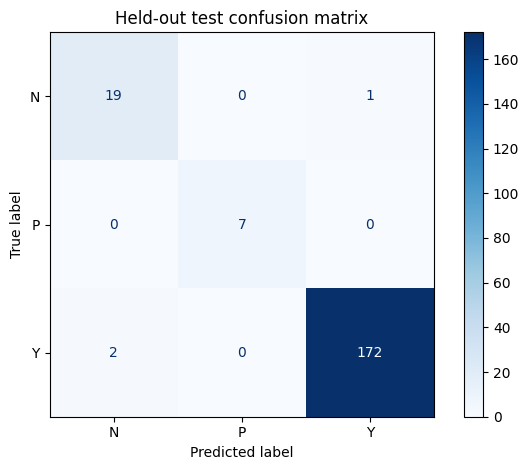

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["N", "P", "Y"],
    cmap="Blues"
)

plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

## 10 Error analysis

In [44]:
error_mask = y_test.to_numpy() != test_predictions

error_records = X_test.loc[error_mask].copy()
error_records["Actual"] = y_test.to_numpy()[error_mask]
error_records["Predicted"] = test_predictions[error_mask]

display(error_records)

,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,Actual,Predicted
75,M,59,4.7,58,4.1,6.3,0.6,1.1,4.9,1.1,24.0,N,Y
181,F,45,3.1,54,4.0,5.9,1.8,1.6,3.5,0.8,24.0,Y,N
216,M,34,7.7,80,5.5,5.1,1.2,1.4,0.9,1.5,21.0,Y,N


The three held-out errors were one N record predicted as Y and two Y records predicted as N. No P errors occurred among the seven P test records. These examples show remaining N–Y confusion. The cause cannot be established from these records alone, and no model changes were made after examining test results.

## 11 Classification and clustering comparison

Classification and clustering answered different questions. Random forest learned from known labels and achieved held-out macro-F1 of 0.973. K-means formed groups without labels, achieving training silhouette of 0.183 and ARI of 0.572. Its clusters only partly matched the classes, including a small group with high Urea and Cr. These scores are not directly comparable because the tasks, metrics, and evaluation settings differ.

## 12 Limitations

ID and No_Pation are not unique, and their meaning is uncertain. Grouped splitting prevented identical feature records from crossing evaluation boundaries, but it does not guarantee that different records from the same patient stayed together. Reported performance may therefore overestimate generalization to entirely new patients. Verified patient identifiers would enable a stronger patient-level evaluation.

The test set includes only seven P records; perfect P recall is sensitive to individual cases. Measurement units, unusual values and label provenance were not independently verified. HbA1c may relate to the process used to assign labels, but that process is unknown. Initial whole-dataset inspection informed the audit, so this is an educational retrospective evaluation, not prospective clinical validation. Clustering was evaluated on training data only.

## 13 Future enhancements

- Verify patient identifiers and evaluate with confirmed patient groups.
- Confirm units and label provenance; investigate flagged values before correction.
- Obtain more N and P records and an independent validation dataset.
- Compare class weighting and limited tuning within training-only grouped validation.
- Assess alternative K values, random seeds, robust preprocessing and clustering methods.
- Evaluate revisions on new untouched data rather than tune repeatedly on the existing test set.

## 14 Conclusion

Random forest was selected by grouped CV macro-F1 (0.915 versus 0.658 for logistic regression). Held-out macro-F1 was 0.973 with three errors among 201 records. K-means showed partial class agreement (ARI 0.572) and limited separation (silhouette 0.183). Uncertain patient identity and the small minority test sample constrain generalization claims.

Dataset source specified by the assignment: https://data.mendeley.com/datasets/wj9rwkp9c2/1. Package versions are recorded in requirements.txt.